# 06 — Robustness of the Feature Clusters and Their Results

**Goal:** check whether the results of NB04 (FC1–FC19) and NB05 (scorecard, permutation test) depend on the choices made along the pipeline. Every check repeats part of the pipeline with a different choice and scores the result with the **same rules** as NB05 (`src/event_scoring.py`). The official FCs, the scorecard and the expert sheet are **not changed** here.

**Order (pipeline order):**
1. Anomaly thresholds (z-score threshold, minimum activated features; NB04 §1)
2. Cut height of the clustering tree (NB04 §3)
3. Clustering on sensors instead of features (NB04 §3; supervisor feedback on same-sensor aggregations)

**Rule:** choices are judged on the training period; the test period only shows whether a result holds.

**Depends on:** NB04 artifacts (`outputs/nb04_artifacts/`) and the NB05 scorecard and permutation test (`outputs/nb05_artifacts/fc_scorecard.csv`, `permutation_test.csv`).

In [1]:
import os, sys, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import pdist
from sklearn.metrics import adjusted_rand_score
warnings.filterwarnings('ignore')

ROOT = os.path.abspath('..')
sys.path.insert(0, ROOT)
from src.event_scoring import EventScorer, p_holm, p_bh

OUT = os.path.join(ROOT, 'outputs')
A = os.path.join(OUT, 'nb04_artifacts')
NB05_OUT = os.path.join(OUT, 'nb05_artifacts')
NB06_OUT = os.path.join(OUT, 'nb06_artifacts')
os.makedirs(NB06_OUT, exist_ok=True)

all_sup = pd.read_parquet(os.path.join(A, 'all_sup.parquet'))
all_sup['window_end'] = pd.to_datetime(all_sup['window_end'])
anom_activations = pd.read_parquet(os.path.join(A, 'anom_activations.parquet'))
anom_meta = pd.read_parquet(os.path.join(A, 'anom_meta.parquet'))
anom_orig_idx = np.load(os.path.join(A, 'anom_orig_idx.npy'))
anom_activations.index = pd.Index(anom_orig_idx)
anom_meta.index = pd.Index(anom_orig_idx)
fail_events = pd.read_parquet(os.path.join(A, 'fail_events.parquet'))
with open(os.path.join(A, 'heuristic_a.json')) as f:
    clusters = {int(k): v for k, v in json.load(f).items()}
with open(os.path.join(A, 'constants.json')) as f:
    constants = json.load(f)
SPLIT_DATE = pd.Timestamp(constants['SPLIT_DATE'])
WINDOW_S = constants['WINDOW_S']
fc_ids = sorted(clusters.keys())

# FC activation on every window (False for non-anomalous windows), as in NB05
fc_act_all = pd.DataFrame(False, index=all_sup.index, columns=fc_ids)
for fc in fc_ids:
    fc_act_all.loc[anom_orig_idx, fc] = anom_activations[clusters[fc]].any(axis=1).values

# Official results from NB05
fc_scores = pd.read_csv(os.path.join(NB05_OUT, 'fc_scorecard.csv'))
perm = pd.read_csv(os.path.join(NB05_OUT, 'permutation_test.csv'))

# Shared scoring rules (src/event_scoring.py)
scorer = EventScorer(all_sup, fail_events, SPLIT_DATE, WINDOW_S)
GAP, chance = scorer.gap, scorer.chance
make_episodes, score_episodes, score_activation = scorer.make_episodes, scorer.score_episodes, scorer.score_activation
fast_score, win_time, order, win_per_day = scorer.fast_score, scorer.win_time, scorer.order, scorer.win_per_day
N_PERM = 2000


def activation(feats):
    act = pd.Series(False, index=all_sup.index)
    act.loc[anom_orig_idx] = anom_activations[feats].any(axis=1).values
    return act


feat_to_fc = {f: fc for fc, feats in clusters.items() for f in feats}
robust = fc_scores.loc[fc_scores.test_check == 'holds', 'fc_id'].tolist()
anchors = {fc: clusters[fc][0] for fc in robust}

# The shared scoring reproduces the NB05 scorecard
sc = fc_scores.set_index('fc_id')
for fc in fc_ids:
    s = score_activation(fc_act_all[fc])
    assert np.isclose(s['lift_train'], sc.loc[fc, 'lift_train']) and np.isclose(s['lift_test'], sc.loc[fc, 'lift_test']), fc
print(f'Windows: {len(all_sup):,} | FCs: {len(clusters)} | robust FCs (test check holds): {", ".join(f"FC{fc}" for fc in robust)}')
print('Shared scoring reproduces the NB05 scorecard lift for all FCs.')

Windows: 64,522 | FCs: 19 | robust FCs (test check holds): FC5, FC7, FC8
Shared scoring reproduces the NB05 scorecard lift for all FCs.


## 1. Robustness to the Anomaly Thresholds

NB04 marks a window as anomalous if at least **5** features have **|z| > 3** (NB04 §1.2–1.4). This check repeats the whole chain for neighbouring settings, z ∈ {2.5, 3.0, 3.5} × minimum ∈ {3, 5, 10}:

1. z-scores against the normal training windows (unchanged), anomalous windows with the new thresholds
2. feature clustering on the **training-period** anomalous windows with the same rules as NB04 (features active in ≥ 1% of those windows, Jaccard distance, average linkage, cut 0.7)
3. **agreement** with FC1–FC19: Adjusted Rand Index (ARI; 1 = identical grouping, 0 = chance level) on the features present in both clusterings
4. for each robust FC (test check holds), the cluster that contains its **anchor feature** (as in §2) is scored with the same event-level rules: lift and coverage on train and test, KEEP verdict on train, test check on test

The official FCs stay at z > 3, ≥ 5. Nothing here is chosen on the test period; the test columns only show whether a finding holds.

In [2]:
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import pdist
from sklearn.metrics import adjusted_rand_score

with open(os.path.join(A, 'feature_cols.json')) as f:
    sensor_feats = json.load(f)
ref = all_sup[(all_sup['split'] == 'train') & (all_sup['label'] == 0)][sensor_feats]
abs_z_all = ((all_sup[sensor_feats] - ref.mean()) / ref.std().replace(0, 1)).abs()
del ref
train_win = (all_sup['split'] == 'train').values
feat_to_fc = {f: fc for fc, feats in clusters.items() for f in feats}
official = pd.Series(feat_to_fc)


def run_setting(z_thr, min_act):
    act = abs_z_all > z_thr
    anom = (act.sum(axis=1) >= min_act).values
    fit = act.values[anom & train_win]
    freq = fit.sum(axis=0)
    keep = freq >= max(int(fit.shape[0] * 0.01), 2)
    feats = [f for f, k in zip(sensor_feats, keep) if k]
    lab = fcluster(linkage(pdist(fit[:, keep].T, metric='jaccard'), method='average'), t=0.7, criterion='distance')
    groups = {}
    for f, l in zip(feats, lab):
        groups.setdefault(int(l), []).append(f)
    return act, anom, feats, pd.Series(lab, index=feats), list(groups.values())


rows = []
for z_thr in (2.5, 3.0, 3.5):
    for min_act in (3, 5, 10):
        act, anom, feats, lab, groups = run_setting(z_thr, min_act)
        common = [f for f in feats if f in official.index]
        ari = adjusted_rand_score(official[common], lab[common])
        base = {'z': z_thr, 'min_act': min_act, 'anomalous_%': 100 * anom.mean(), 'n_clusters': len(groups),
                'n_feats': len(feats), 'ARI_vs_official': ari}
        for fc in robust:
            a = anchors[fc]
            row = dict(base, FC=f'FC{fc}', anchor=a)
            if a not in lab.index:
                row.update(found=False)
            else:
                g = [f for f in feats if lab[f] == lab[a]]
                s = pd.Series(False, index=all_sup.index)
                s[anom] = act.loc[anom, g].any(axis=1).values
                row.update(found=True, cluster_size=len(g),
                           overlap_with_official=len(set(g) & set(clusters[fc])) / len(set(g) | set(clusters[fc])),
                           **score_activation(s))
            rows.append(row)
thr_rob = pd.DataFrame(rows)
thr_rob.to_csv(os.path.join(NB06_OUT, 'threshold_robustness.csv'), index=False)

summary = thr_rob.drop_duplicates(['z', 'min_act'])[['z', 'min_act', 'anomalous_%', 'n_feats', 'n_clusters', 'ARI_vs_official']]
print('Clustering per setting (official: z > 3.0, min 5):')
print(summary.round(3).to_string(index=False))
for fc in robust:
    t = thr_rob[thr_rob.FC == f'FC{fc}']
    print(f'\nFC{fc} (anchor {anchors[fc]}):')
    print(t[['z', 'min_act', 'found', 'cluster_size', 'overlap_with_official', 'lift_train', 'covered_train', 'verdict',
             'lift_test', 'covered_test', 'test_check']].round(2).to_string(index=False))
held = thr_rob.groupby('FC').apply(lambda t: f"KEEP {(t.verdict == 'KEEP').sum()}/{len(t)}, test check holds {(t.test_check == 'holds').sum()}/{len(t)}")
print('\nAcross the 9 settings: ' + ' | '.join(f'{k}: {v}' for k, v in held.items()))

Clustering per setting (official: z > 3.0, min 5):
  z  min_act  anomalous_%  n_feats  n_clusters  ARI_vs_official
2.5        3       39.329      134          24            0.946
2.5        5       32.589      144          23            0.963
2.5       10       24.418      149          18            0.822
3.0        3       29.254      126          21            0.974
3.0        5       18.632      126          19            1.000
3.0       10       11.557      124          16            0.830
3.5        3       19.962      122          17            0.926
3.5        5       13.259      121          15            0.885
3.5       10       10.479      118          12            0.814

FC5 (anchor CW2_COMPRESSOR_RUNNING_flips):
  z  min_act  found  cluster_size  overlap_with_official  lift_train  covered_train verdict  lift_test  covered_test test_check
2.5        3   True             1                    1.0        2.33              8    KEEP       1.42            10      fails
2.5      

## 2. Sensitivity to the Cut Height of the Clustering

The FCs come from cutting NB04's feature tree (Jaccard distance, average linkage, train-period anomalous windows) at a distance of **0.7**. That value is a choice, and three FCs are single features that sit just above it (FC4 and FC5 are 0.708 apart). This check re-cuts the **same tree** at other heights and asks whether the robust FCs (those whose test check holds) keep their result.

- The tree is rebuilt from the saved NB04 inputs, and the cut at 0.7 must reproduce FC1–FC19 exactly (asserted).
- FC numbers change with every cut, so each robust FC is followed by its **first feature** (the anchor): at each height, the cluster containing the anchor is scored with the same event-level rules as the scorecard above (lift and coverage on train and test, KEEP verdict on train, test check on test).
- `stable_range` is the interval of cut heights (step 0.01) in which the anchor's cluster has exactly the same members as today's FC.
- The figure below follows the same anchors over all cut heights from 0.50 to 0.95 (panel a: number of clusters; panels b–d: lift on train and test events, grey where the test check fails).
- This is a robustness check only. The official FCs, the verdicts and the expert sheet stay at 0.7, and nothing here is chosen on the test period.

In [3]:
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import pdist

with open(os.path.join(A, 'active_feats.json')) as f:
    active_feats = json.load(f)
fit_mask = (anom_meta['split'] == 'train').values
Z_tree = linkage(pdist(anom_activations.loc[fit_mask, active_feats].values.T, metric='jaccard'), method='average')


def cut_tree(t):
    groups = {}
    for f, cl in zip(active_feats, fcluster(Z_tree, t=t, criterion='distance')):
        groups.setdefault(int(cl), []).append(f)
    return list(groups.values())


assert sorted(map(sorted, cut_tree(0.7))) == sorted(map(sorted, clusters.values())), 'cut at 0.7 does not reproduce FC1-FC19'


# score_activation, activation, feat_to_fc, robust and anchors come from the setup cell

# Sanity check: at 0.7 the helper reproduces the scorecard
for fc in robust:
    s = score_activation(activation(clusters[fc]))
    ref = fc_scores.set_index('fc_id').loc[fc]
    assert np.isclose(s['lift_train'], ref.lift_train) and np.isclose(s['lift_test'], ref.lift_test), fc

fine = np.round(np.arange(0.50, 0.951, 0.01), 2)
fine_cuts = {t: cut_tree(t) for t in fine}
stable = {}
for fc, a in anchors.items():
    same = [t for t in fine if set(next(g for g in fine_cuts[t] if a in g)) == set(clusters[fc])]
    stable[fc] = f'{min(same):.2f}-{max(same):.2f}'

CUTS = [0.60, 0.65, 0.70, 0.75, 0.80]
rows = []
for t in CUTS:
    groups = cut_tree(t)
    for fc, a in anchors.items():
        g = next(g for g in groups if a in g)
        rows.append({'cut': t, 'n_clusters': len(groups), 'n_singletons': sum(len(x) == 1 for x in groups),
                     'anchor_of': f'FC{fc}', 'anchor_feature': a, 'cluster_size': len(g),
                     'contains_FCs_at_0.7': ', '.join(f'FC{c}' for c in sorted({feat_to_fc[f] for f in g})),
                     **score_activation(activation(g)), 'stable_range': stable[fc]})
sens = pd.DataFrame(rows)
sens.to_csv(os.path.join(NB06_OUT, 'cluster_sensitivity.csv'), index=False)

print('Cut height vs number of clusters:',
      ', '.join(f'{t:.2f}: {len(fine_cuts[round(t, 2)])} ({sum(len(x) == 1 for x in fine_cuts[round(t, 2)])} single)' for t in CUTS))
for fc in robust:
    print(f'\nFC{fc} (anchor {anchors[fc]}), same members for cut heights {stable[fc]}')
    print(sens[sens.anchor_of == f'FC{fc}'][['cut', 'cluster_size', 'contains_FCs_at_0.7', 'lift_train', 'covered_train',
                                              'verdict', 'lift_test', 'covered_test', 'test_check']].round(2).to_string(index=False))
held = sens.groupby('anchor_of')['test_check'].apply(lambda s: (s == 'holds').sum())
print('\nTest check holds at how many of the', len(CUTS), 'cut heights:', ', '.join(f'{k} {v}/{len(CUTS)}' for k, v in held.items()))

Cut height vs number of clusters: 0.60: 25 (8 single), 0.65: 21 (5 single), 0.70: 19 (3 single), 0.75: 12 (0 single), 0.80: 10 (0 single)

FC5 (anchor CW2_COMPRESSOR_RUNNING_flips), same members for cut heights 0.50-0.70
 cut  cluster_size contains_FCs_at_0.7  lift_train  covered_train verdict  lift_test  covered_test test_check
0.60             1                 FC5        3.69              4    KEEP       1.92             8      holds
0.65             1                 FC5        3.69              4    KEEP       1.92             8      holds
0.70             1                 FC5        3.69              4    KEEP       1.92             8      holds
0.75             2            FC4, FC5        3.01              4    KEEP       1.44            10      fails
0.80             2            FC4, FC5        3.01              4    KEEP       1.44            10      fails

FC7 (anchor CW1_SPRING_BRAKE_PRESSURE_BOGIE2_min), same members for cut heights 0.50-0.84
 cut  cluster_size contains_

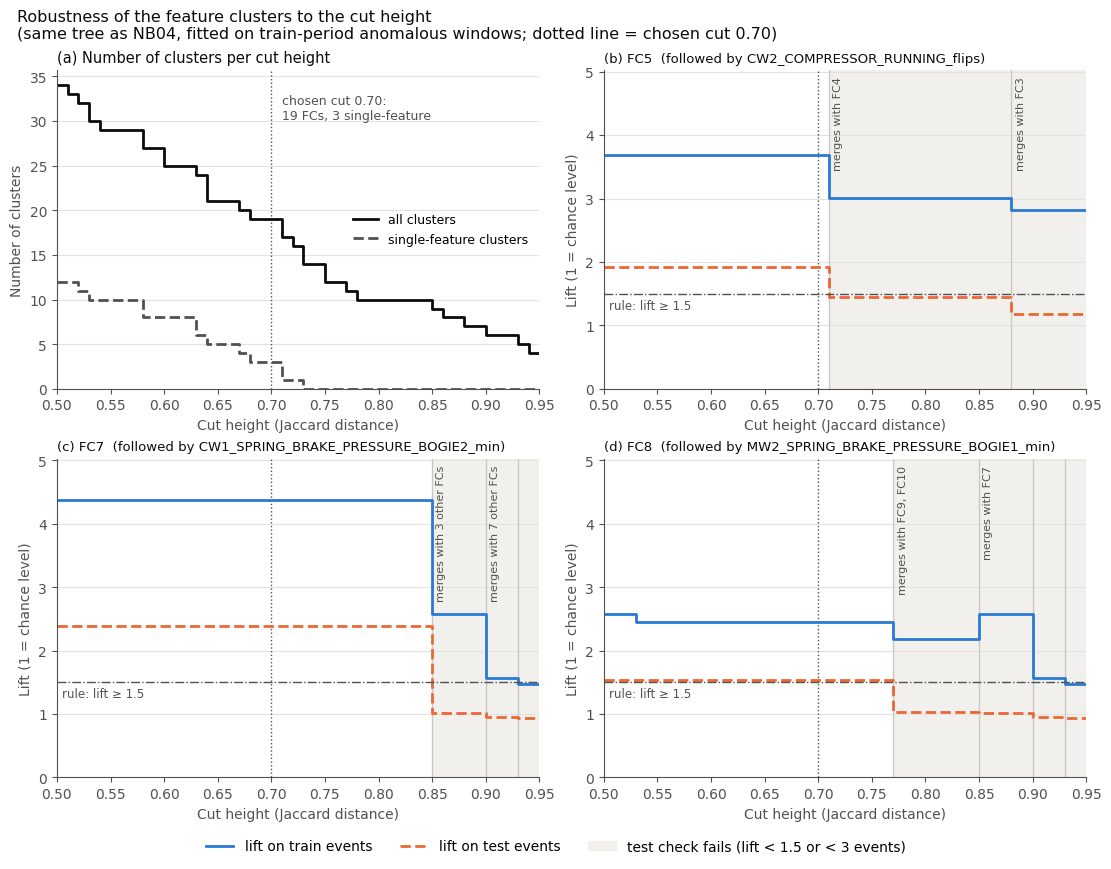

In [4]:
# Figure: lift of the robust FCs and number of clusters across cut heights
from matplotlib.patches import Patch

INK, INK2, GRID, MERGE, FAILBG = '#0b0b0b', '#52514e', '#e4e3df', '#c9c8c3', '#f1f0ec'
C_TRAIN, C_TEST = '#2a78d6', '#eb6834'
THR = 1.5

score_cache = {}
def cached_score(g):
    k = frozenset(g)
    if k not in score_cache:
        score_cache[k] = score_activation(activation(sorted(g)))
    return score_cache[k]

curves = {}
for fc, a in anchors.items():
    rows = []
    for t in fine:
        g = next(g for g in fine_cuts[t] if a in g)
        rows.append({'cut': t, 'size': len(g), 'fcs': tuple(sorted({feat_to_fc[f] for f in g})), **cached_score(g)})
    curves[fc] = pd.DataFrame(rows)

with plt.rc_context({'font.size': 10, 'axes.edgecolor': INK2, 'axes.labelcolor': INK2, 'xtick.color': INK2,
                     'ytick.color': INK2, 'axes.spines.top': False, 'axes.spines.right': False}):
    fig, axes = plt.subplots(2, 2, figsize=(11, 8.2), constrained_layout=True)
    axes = axes.ravel()

    def common(ax):
        ax.axvline(0.70, color=INK2, lw=1, ls=':', zorder=1)
        ax.grid(axis='y', color=GRID, lw=0.8)
        ax.set_axisbelow(True)
        ax.set_xlim(fine.min(), fine.max())
        ax.set_xlabel('Cut height (Jaccard distance)')

    # (a) number of clusters and single-feature clusters
    ax = axes[0]
    n_cl = [len(fine_cuts[t]) for t in fine]
    n_si = [sum(len(x) == 1 for x in fine_cuts[t]) for t in fine]
    ax.step(fine, n_cl, where='post', color=INK, lw=2, label='all clusters')
    ax.step(fine, n_si, where='post', color=INK2, lw=2, ls='--', label='single-feature clusters')
    common(ax)
    n_single = sum(len(v) == 1 for v in clusters.values())
    ax.text(0.71, max(n_cl) * 0.97, f'chosen cut 0.70:\n{len(clusters)} FCs, {n_single} single-feature',
            color=INK2, fontsize=9, va='top')
    ax.set_ylabel('Number of clusters')
    ax.set_ylim(0, None)
    ax.set_title('(a) Number of clusters per cut height', loc='left', color=INK, fontsize=10.5)
    ax.legend(frameon=False, loc='center right', fontsize=9)

    # (b-d) lift of each robust FC's cluster (followed by its anchor feature)
    ymax = max(max(c.lift_train.max(), c.lift_test.max()) for c in curves.values()) * 1.15
    for i, (fc, c) in enumerate(curves.items()):
        ax = axes[i + 1]
        for t, f in zip(c.cut, c.test_check == 'fails'):
            if f:
                ax.axvspan(t, t + 0.01, color=FAILBG, lw=0, zorder=0)
        ax.step(c.cut, c.lift_train, where='post', color=C_TRAIN, lw=2, label='lift on train events')
        ax.step(c.cut, c.lift_test, where='post', color=C_TEST, lw=2, ls='--', label='lift on test events')
        ax.axhline(THR, color=INK2, lw=1, ls='-.')
        ax.text(0.505, THR - 0.08, 'rule: lift ≥ 1.5', color=INK2, fontsize=8.5, va='top')
        common(ax)
        prev, n_marks = c.fcs.iloc[0], 0
        for t, fcs in zip(c.cut, c.fcs):
            new = [f'FC{x}' for x in fcs if x not in prev]
            if new:
                ax.axvline(t, color=MERGE, lw=1, zorder=1)
                if n_marks < 2:  # label the first two merges; later ones (everything collapsing) get a line only
                    lab = 'merges with ' + (', '.join(new) if len(new) <= 2 else f'{len(new)} other FCs')
                    ax.text(t + 0.004, ymax * 0.98, lab, fontsize=8, color=INK2, va='top', ha='left', rotation=90)
                n_marks += 1
            prev = fcs
        ax.set_ylim(0, ymax)
        ax.set_ylabel('Lift (1 = chance level)')
        ax.set_title(f'({chr(98 + i)}) FC{fc}  (followed by {anchors[fc]})', loc='left', color=INK, fontsize=9.5)

    h, l = axes[1].get_legend_handles_labels()
    fig.legend(h + [Patch(color=FAILBG)], l + ['test check fails (lift < 1.5 or < 3 events)'],
               loc='lower center', bbox_to_anchor=(0.5, -0.05), ncol=3, frameon=False)
    fig.suptitle('Robustness of the feature clusters to the cut height\n'
                 '(same tree as NB04, fitted on train-period anomalous windows; dotted line = chosen cut 0.70)',
                 x=0.01, ha='left', color=INK, fontsize=11.5)
    fig.savefig(os.path.join(NB06_OUT, 'cluster_sensitivity.png'), dpi=150, bbox_inches='tight')
    plt.show()

## 3. Sensor-Level Robustness: Do the Findings Depend on Clustering Aggregations?

The FCs group **features**, and several aggregations of the same sensor (min, mean, max) often land in the same FC because a level shift moves all of them at once (supervisor feedback; NB04 counts 35 same-sensor duplicates among the 126 clustered features, and FC13 consists of one sensor only). This inflates cluster sizes and gives sensors with several aggregations more weight.

This check repeats the clustering on **sensors** instead of features:
1. the **same anomalous windows** as NB04 (z > 3, at least 5 activated features), so only the clustering unit changes
2. a sensor is **activated** in a window if any of its aggregations is activated
3. the same clustering rules as NB04 on the training-period anomalous windows: sensors active in ≥ 1% of those windows, Jaccard distance, average linkage, cut 0.7 → **sensor clusters (SC)**
4. each FC is matched to the sensor cluster with the largest overlap of sensors (Jaccard of the sensor sets)
5. every sensor cluster is scored with the same event-level rules and the **permutation test of NB05 §3.1** (train decides; test only checks)

Aggregations stay in the official FCs, because which aggregation fires (min: dips, max: spikes, all: level shift) is informative and min/max carry most of the separation (NB03a §4); this check only asks whether the findings survive without them.

In [5]:
# ── 3.5 Sensor-level clustering on the same anomalous windows ──
def sensor_of(f):
    for suf in ('_active_s', '_flips', '_min', '_max', '_mean', '_sum'):
        if f.endswith(suf):
            return f[:-len(suf)]
    return f


feat_cols_anom = list(anom_activations.columns)
sensors = sorted({sensor_of(f) for f in feat_cols_anom})
sens_act = pd.DataFrame({s: anom_activations[[f for f in feat_cols_anom if sensor_of(f) == s]].any(axis=1) for s in sensors})
fit_s = sens_act.values[(anom_meta['split'] == 'train').values]
keep_s = fit_s.sum(axis=0) >= max(int(fit_s.shape[0] * 0.01), 2)
act_sensors = [s for s, k in zip(sensors, keep_s) if k]
lab_s = fcluster(linkage(pdist(fit_s[:, keep_s].T, metric='jaccard'), method='average'), t=0.7, criterion='distance')
sc_groups = {}
for s, l in zip(act_sensors, lab_s):
    sc_groups.setdefault(int(l), []).append(s)
sc_ids = sorted(sc_groups, key=lambda k: (-len(sc_groups[k]), sc_groups[k][0]))
sc_groups = {i + 1: sc_groups[k] for i, k in enumerate(sc_ids)}
n_feat_sensors = len({sensor_of(f) for feats in clusters.values() for f in feats})
print(f'Sensors: {len(sensors)} | active in >= 1% of train anomalous windows: {len(act_sensors)} '
      f'(FC1-FC19 cover {n_feat_sensors} sensors) | sensor clusters: {len(sc_groups)} (FCs: {len(clusters)})')

# Match every FC to the sensor cluster with the largest sensor overlap
fc_sensors = {fc: {sensor_of(f) for f in feats} for fc, feats in clusters.items()}
match_rows = []
for fc in fc_ids:
    best = max(sc_groups, key=lambda k: len(fc_sensors[fc] & set(sc_groups[k])) / len(fc_sensors[fc] | set(sc_groups[k])))
    j = len(fc_sensors[fc] & set(sc_groups[best])) / len(fc_sensors[fc] | set(sc_groups[best]))
    match_rows.append({'FC': f'FC{fc}', 'fc_sensors': len(fc_sensors[fc]), 'best_SC': f'SC{best}',
                       'sc_sensors': len(sc_groups[best]), 'sensor_overlap': j})
match = pd.DataFrame(match_rows)


def sensor_activation(group):
    s = pd.Series(False, index=all_sup.index)
    s.loc[anom_orig_idx] = sens_act[group].any(axis=1).values
    return s


rng_s = np.random.default_rng(7)
sc_rows = []
for k, group in sc_groups.items():
    s = sensor_activation(group)
    row = {'SC': f'SC{k}', 'n_sensors': len(group), 'sensors': ', '.join(group), **score_activation(s)}
    for sp in ('train', 'test'):
        a = s.values[order[sp]]
        t_sp = win_time[order[sp]]
        obs, cov = fast_score(t_sp[a], sp)
        n = len(a)
        min_shift = int(7 * win_per_day[sp])
        null = np.array([fast_score(t_sp[np.roll(a, sh)], sp)[0] for sh in rng_s.integers(min_shift, n - min_shift, size=N_PERM)])
        row[f'p_{sp}'] = (1 + (null >= obs).sum()) / (1 + N_PERM)
    sc_rows.append(row)
sc_df = pd.DataFrame(sc_rows)
for sp in ('train', 'test'):
    sc_df[f'p_bh_{sp}'] = p_bh(sc_df[f'p_{sp}'])
    sc_df[f'significant_{sp}'] = (sc_df[f'p_bh_{sp}'] < 0.05) & (sc_df[f'covered_{sp}'] >= 3)
sc_df.to_csv(os.path.join(NB06_OUT, 'sensor_level_clusters.csv'), index=False)
match.to_csv(os.path.join(NB06_OUT, 'fc_to_sensor_cluster.csv'), index=False)

print('\nFC -> best-matching sensor cluster (sensor_overlap = Jaccard of the sensor sets; 1 = same sensors):')
print(match.round(2).to_string(index=False))
print('\nSensor clusters, event-level score and permutation test (train decides, test checks):')
print(sc_df[['SC', 'n_sensors', 'lift_train', 'covered_train', 'p_bh_train', 'significant_train',
             'lift_test', 'covered_test', 'p_bh_test', 'significant_test', 'sensors']].round(3).to_string(index=False, max_colwidth=70))

print(f'\nFeature level (NB05 §3.1): {perm.significant_train.sum()} of {len(perm)} FCs significant on train, '
      f'{(perm.significant_train & perm.significant_test).sum()} also on test ({", ".join(perm.loc[perm.significant_train & perm.significant_test, "FC"])}).')
both = sc_df[sc_df.significant_train & sc_df.significant_test]
print(f'Sensor level: {sc_df.significant_train.sum()} of {len(sc_df)} sensor clusters significant on train, {len(both)} also on test '
      f'({", ".join(both.SC + " [" + both.sensors + "]") if len(both) else "none"}).')
for fc in robust:
    m = match[match.FC == f'FC{fc}'].iloc[0]
    r = sc_df[sc_df.SC == m.best_SC].iloc[0]
    print(f'  FC{fc} ({", ".join(sorted(fc_sensors[fc]))}) -> {m.best_SC} (overlap {m.sensor_overlap:.2f}): '
          f'significant train {r.significant_train}, test {r.significant_test}')

Sensors: 93 | active in >= 1% of train anomalous windows: 68 (FC1-FC19 cover 68 sensors) | sensor clusters: 10 (FCs: 19)



FC -> best-matching sensor cluster (sensor_overlap = Jaccard of the sensor sets; 1 = same sensors):
  FC  fc_sensors best_SC  sc_sensors  sensor_overlap
 FC1          12     SC2          13            0.92
 FC2           1     SC2          13            0.08
 FC3           4     SC7           4            1.00
 FC4           1     SC9           1            1.00
 FC5           1    SC10           1            1.00
 FC6          10     SC3          10            1.00
 FC7           2     SC5           6            0.14
 FC8           7     SC3          10            0.70
 FC9           4     SC5           6            0.11
FC10          16     SC1          18            0.89
FC11           2     SC5           6            0.33
FC12           2     SC8           2            1.00
FC13           1     SC4           8            0.12
FC14           4     SC5           6            0.67
FC15           3     SC4           8            0.38
FC16           2     SC4           8            0.2

## Traceability: Pipeline Position

**NB01 → NB02a → NB03a → NB04 → NB05 → NB06** (clustering branch); **NB02a → NB02b → NB03b** (baseline branch)

### What this notebook provides
- §1: the findings under neighbouring anomaly thresholds (z ∈ {2.5, 3, 3.5} × minimum ∈ {3, 5, 10})
- §2: the cut height of the clustering tree (0.50–0.95)
- §3: clustering on sensors instead of features (same-sensor aggregations)
- No official result is changed; NB05 and the expert sheet keep FC1–FC19 at z > 3, ≥ 5, cut 0.7

### Outputs (`outputs/nb06_artifacts/`)
- `threshold_robustness.csv`, `cluster_sensitivity.csv/.png`, `sensor_level_clusters.csv`, `fc_to_sensor_cluster.csv`